# IV. Temporalité

**Objectif** : Comprendre les habitudes temporelles de commande des clients (moment de la semaine et de la journée), afin d'identifier les périodes de forte affluence et les comportements de commandes répétées sur une même journée.

**Questions à traiter** :

1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?
2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

**Impact business attendu** : 
Identifier les pics d'activité pour optimiser les ressources (stocks, personnel, capacité de livraison) aux moments clés, et détecter des comportements de commandes fractionnées pouvant révéler des frictions dans l'expérience d'achat.

## Setup

In [6]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import get_data
from src.features import enrich_dataframe
from src.data_loader import load_raw_data

raw = load_raw_data(raw_dir="../data/raw")
orders = raw["orders"]

sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

data = get_data(raw_dir="../data/raw", processed_path="../data/processed/merged_orders.parquet")
data = enrich_dataframe(data)

print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]} colonnes")

Chargement depuis le cache .parquet
Dataset: 10,737,546 lignes, 22 colonnes


## 1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?

**Hypothèse à tester :** on suppose que les clients commandent davantage en semaine, éventuellement pour anticiper une livraison ou une consommation le week-end.

On mesure ici le nombre de commandes passées (pas de produits achetés) par jour de la semaine et heure de la journée. Comme `data` contient une ligne par produit dans une commande, on déduplique d'abord par `order_id` pour ne compter chaque commande qu'une seule fois, quelle que soit la taille de son panier. On réutilise la colonne `day_name`, déjà construite par `enrich_dataframe()`.

In [12]:
orders_time = data.drop_duplicates(subset="order_id")[["order_id", "day_name", "order_hour_of_day"]]
orders_time.shape

(1064689, 3)

In [18]:
heatmap_data = orders_time.groupby(["day_name", "order_hour_of_day"], observed=True).size().unstack(fill_value=0)

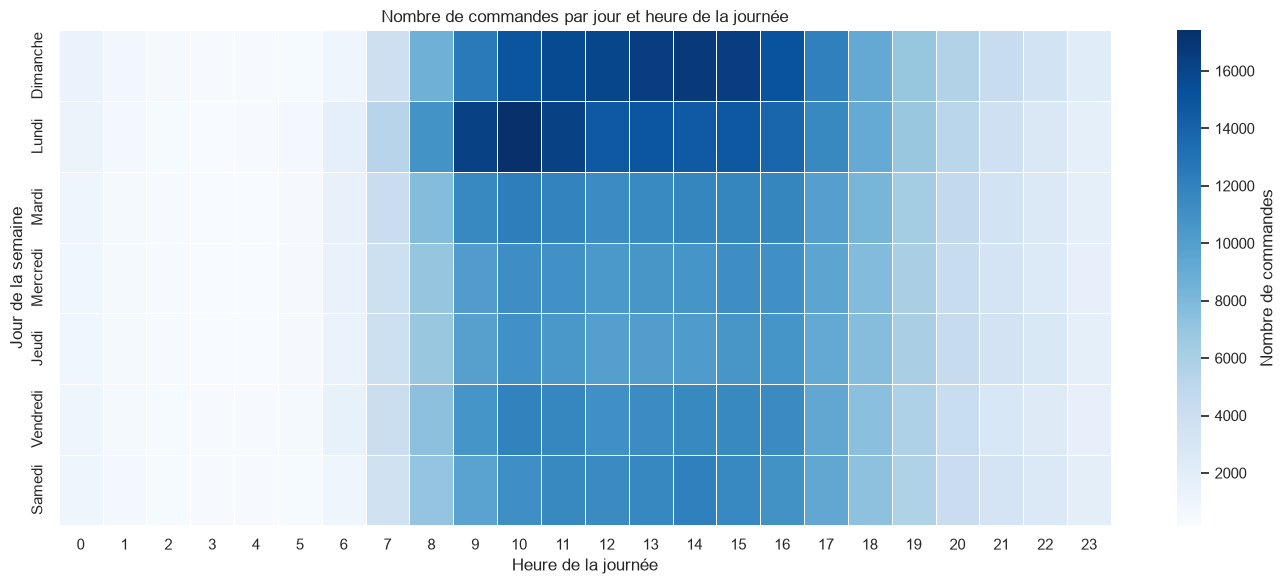

In [17]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    heatmap_data,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Nombre de commandes"},
    ax=ax
)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Jour de la semaine")
ax.set_title("Nombre de commandes par jour et heure de la journée")

plt.tight_layout()
plt.show()

**Réponse à la question :** 
Les commandes se concentrent nettement le week-end et en début de semaine, en particulier le **dimanche** et le **lundi**, avec un pic entre 9h et 16h environ. À l'inverse, les jours du milieu de semaine (mardi à vendredi) affichent une activité plus homogène et globalement plus faible. Les horaires de nuit (0h-6h) restent très peu actifs, tous les jours confondus.

**Vérification de l'hypothèse :** contrairement à l'hypothèse initiale l'activité de commande est en réalité plus forte le week-end et le lundi (et non en semaine). L'hypothèse est donc infirmée : le dataset ne permet cependant pas de distinguer date de commande et date de livraison souhaitée, donc cette observation porte uniquement sur le moment où la commande est passée.

**Implication business :** 
Ces créneaux de forte affluence (dimanche/lundi, milieu de journée) sont les moments à prioriser pour la disponibilité des stocks, la capacité de livraison, et le support client. À l'inverse, les heures creuses (nuit) pourraient être utilisées pour la maintenance technique ou les mises à jour de l'infrastructure sans impacter l'expérience utilisateur.

## 2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

La colonne `days_since_prior_order` indique le nombre de jours écoulés depuis la commande précédente du même utilisateur. Une valeur de 0 signifie que la commande précédente a eu lieu le même jour. On calcule cette proportion au niveau commande (pas produit), en dédupliquant par `order_id` comme pour la question précédente.

In [19]:
same_day_orders = orders_time.merge(
    data.drop_duplicates(subset="order_id")[["order_id", "days_since_prior_order"]],
    on="order_id"
)

same_day_count = (same_day_orders["days_since_prior_order"] == 0).sum()
total_orders = same_day_orders.shape[0]
same_day_pct = same_day_count / total_orders * 100

print(f"Commandes le même jour que la précédente : {same_day_count:,} sur {total_orders:,} ({same_day_pct:.2f}%)")

Commandes le même jour que la précédente : 21,245 sur 1,064,689 (2.00%)


In [20]:
same_day_by_segment = data.drop_duplicates(subset="order_id")[["order_id", "days_since_prior_order", "customer_segment"]]
same_day_by_segment["same_day"] = same_day_by_segment["days_since_prior_order"] == 0

same_day_rate_by_segment = same_day_by_segment.groupby("customer_segment", observed=True)["same_day"].mean() * 100
same_day_rate_by_segment

customer_segment
occasionnel    0.998329
typique        1.230098
fidèle         2.647929
Name: same_day, dtype: float64

**Résultat :** 
2,00% des commandes sont passées le même jour que la commande précédente de l'utilisateur (21 245 commandes sur 1 064 689). 
Ce taux varie selon le segment client :

Segment - Taux de commandes le même jour
Occasionnel - 1,00% 
Typique - 1,23%
Fidèle - 2,65% 

**Interprétation :** 
Les clients fidèles sont environ 2,6 fois plus susceptibles de recommander le même jour que les clients occasionnels. 
Cet écart peut s'expliquer en partie par un effet mécanique (plus de 
commandes au total = plus d'occasions statistiques de tomber sur ce 
cas de figure), mais pourrait aussi révéler un vrai comportement : des clients qui complètent une commande oubliée, ou qui fractionnent volontairement leurs achats en plusieurs commandes rapprochées.

**Implication business :** 
Ce phénomène, bien que minoritaire, pourrait signaler des frictions dans l'expérience de commande (produit oublié, besoin urgent après coup) plutôt qu'un choix délibéré. 
Il serait pertinent de proposer une fenêtre de modification (par exemple 15 minutes après validation) permettant au client d'ajouter un produit oublié directement à sa commande initiale. Cela répondrait à la cause probable du phénomène tout en évitant des frais de livraison et de traitement dupliqués, aussi bien pour le client que pour la plateforme.

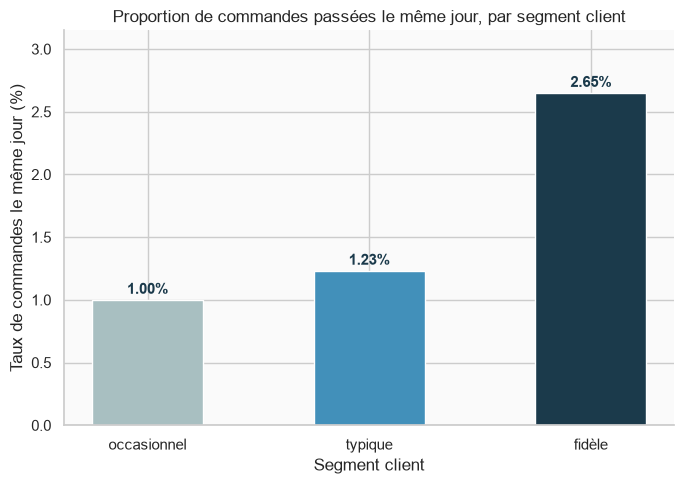

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

segments = same_day_rate_by_segment.index.tolist()
values = same_day_rate_by_segment.values
colors_bar = [COLORS[s] for s in segments]

bars = ax.bar(segments, values, color=colors_bar, width=0.5)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f"{val:.2f}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"])

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de commandes le même jour (%)")
ax.set_title("Proportion de commandes passées le même jour, par segment client")
ax.set_ylim(0, max(values) + 0.5)

plt.tight_layout()
plt.show()

## Conclusion générale — Temporalité

Les deux analyses montrent deux choses complémentaires. D'abord, on peut prévoir globalement quand les commandes arrivent : surtout le dimanche et le lundi, en journée (Q1). Ensuite, on voit que ce rythme n'est pas exactement le même pour tout le monde : les clients fidèles recommandent plus souvent le même jour que les occasionnels, souvent par oubli d'un produit (Q2).

**Recommandation :** 
La plateforme peut planifier ses stocks et sa capacité de livraison à l'avance en se basant sur les créneaux identifiés. Pour réduire les commandes multiples liées à un oubli, une fenêtre de modification après validation (voir Q2) serait une piste concrète à explorer.